# 02 — H3 Axis-Priority Diagnostic

This notebook records the prospectively frozen A-only versus C-only causal priority
diagnostic. It uses saved results only and does not train H3, evaluate a checkpoint,
access TEST, or authorize Phase 15.

In [1]:
from pathlib import Path
import hashlib
import json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

def discover_repo(start=None):
    candidates = []
    if start is not None:
        candidates.append(Path(start).resolve())
    candidates.extend([Path.cwd().resolve(), Path.cwd().resolve().parent])
    try:
        candidates.append(Path(__file__).resolve())
    except NameError:
        pass
    for candidate in candidates:
        current = candidate if candidate.is_dir() else candidate.parent
        for root in (current, *current.parents):
            if all((root / name).is_dir() for name in ("scripts", "reports", "manifests", "notebooks")):
                return root
    fallback = Path(r"D:/Softfors/jup")
    if all((fallback / name).is_dir() for name in ("scripts", "reports", "manifests", "notebooks")):
        return fallback
    raise RuntimeError("Repository root not found: expected scripts/, reports/, manifests/, notebooks/.")

ROOT = discover_repo()
AUDITS = ROOT / "reports" / "audits"
TABLES = ROOT / "reports" / "tables"

def load_json(relative):
    with (ROOT / relative).open("r", encoding="utf-8") as handle:
        return json.load(handle)

def read_csv(relative):
    return pd.read_csv(ROOT / relative)

def sha(relative):
    return hashlib.sha256((ROOT / relative).read_bytes()).hexdigest()

print("Repository root:", ROOT)
print("No training or inference is executed by this notebook.")

Repository root: D:\Softfors\jup
No training or inference is executed by this notebook.


In [2]:
axis = load_json("reports/audits/post_phase14_h3_axis_priority_results.json")
conditions = axis["conditions"]
print("Scientific question: which single causal axis has priority for the missing regional Tiny-recall signal?")
print("Frozen interventions: A_ONLY=GT-assisted supply completion; C_ONLY=FP removal; A+C=upper bound.")

Scientific question: which single causal axis has priority for the missing regional Tiny-recall signal?
Frozen interventions: A_ONLY=GT-assisted supply completion; C_ONLY=FP removal; A+C=upper bound.


## 1. Frozen conditions and complete comparison

In [3]:
rows = []
for condition, metrics in conditions.items():
    rows.append({"condition": condition, **metrics})
comparison = pd.DataFrame(rows)
display(comparison)
quantities = pd.DataFrame([
    ("R_A", axis["causal_quantities"]["R_A"], "A-only retained fraction of Oracle Tiny-recall gap"),
    ("R_C", axis["causal_quantities"]["R_C"], "C-only retained fraction of Oracle Tiny-recall gap"),
    ("R_AC", axis["causal_quantities"]["R_AC"], "A+C retained fraction of Oracle Tiny-recall gap"),
], columns=["quantity", "value", "definition"])
display(quantities)

,condition,dice_mean,fp_components_per_image,recall_overall,recall_TINY,recall_SMALL,recall_MEDIUM,recall_LARGE,recall_hard_tiny,global_empty_recovered
0,GLOBAL,0.635917,0.485437,0.822368,0.791667,0.821429,0.861111,0.8750,0.0,0.0
1,PREDICTED,0.418531,7.776699,0.875000,0.791667,0.892857,1.000000,0.9375,0.0,0.2
2,A_ONLY,0.478039,7.805825,1.000000,1.000000,1.000000,1.000000,1.0000,1.0,1.0
3,C_ONLY,0.628753,0.689320,0.875000,0.791667,0.892857,1.000000,0.9375,0.0,0.2
4,A_PLUS_C,0.737166,0.718447,1.000000,1.000000,1.000000,1.000000,1.0000,1.0,1.0
5,ORACLE_REGIONAL,0.802416,0.631068,1.000000,1.000000,1.000000,1.000000,1.0000,1.0,1.0


,quantity,value,definition
0,R_A,1.0,A-only retained fraction of Oracle Tiny-recall...
1,R_C,0.0,C-only retained fraction of Oracle Tiny-recall...
2,R_AC,1.0,A+C retained fraction of Oracle Tiny-recall gap


## 2. Causal priority visualizations

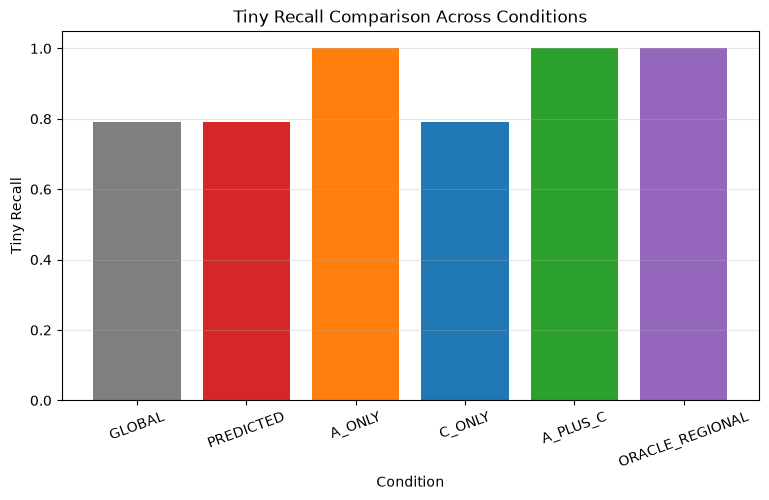

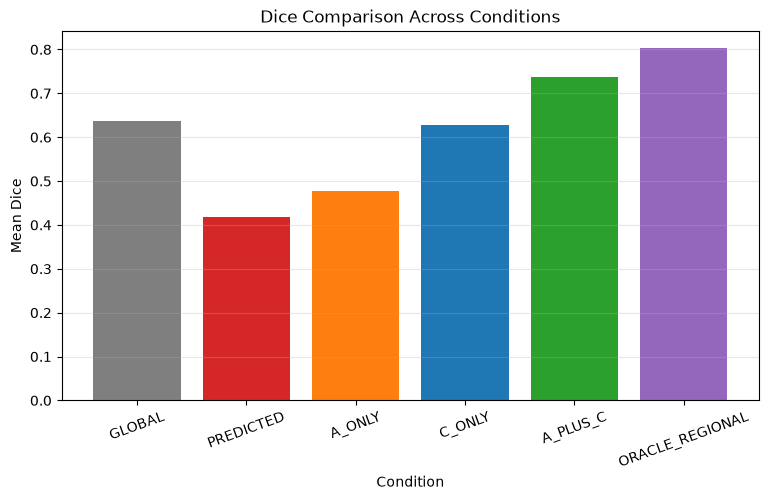

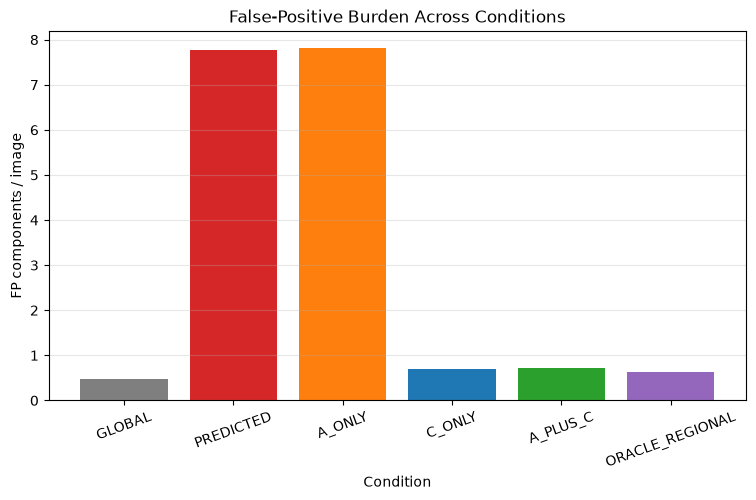

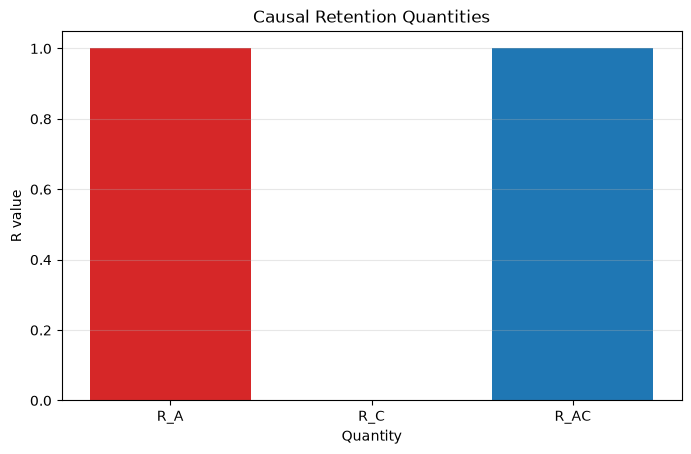

In [4]:
for column, title, ylabel in [
    ("recall_TINY", "Tiny Recall Comparison Across Conditions", "Tiny Recall"),
    ("dice_mean", "Dice Comparison Across Conditions", "Mean Dice"),
    ("fp_components_per_image", "False-Positive Burden Across Conditions", "FP components / image"),
]:
    fig, ax = plt.subplots(figsize=(9, 4.8))
    ax.bar(comparison["condition"], comparison[column], color=["tab:gray", "tab:red", "tab:orange", "tab:blue", "tab:green", "tab:purple"])
    ax.set(title=title, xlabel="Condition", ylabel=ylabel)
    ax.tick_params(axis="x", rotation=20); ax.grid(True, axis="y", alpha=0.3); plt.show()
fig, ax = plt.subplots(figsize=(8, 4.8))
r = quantities["value"]
ax.bar(quantities["quantity"], r, color=["tab:red", "tab:orange", "tab:blue"])
ax.set(title="Causal Retention Quantities", xlabel="Quantity", ylabel="R value")
ax.grid(True, axis="y", alpha=0.3); plt.show()

## 3. Necessity, sufficiency, and priority rule

In [5]:
necessity = pd.DataFrame([
    ("A_supply", axis["causal_necessity"]["A_supply"]),
    ("C_contamination", axis["causal_necessity"]["C_contamination"]),
], columns=["axis", "causal necessity"])
sufficiency = pd.DataFrame([
    ("A_supply", axis["causal_sufficiency"]["A_supply"]),
    ("C_contamination", axis["causal_sufficiency"]["C_contamination"]),
], columns=["axis", "causal sufficiency"])
display(necessity); display(sufficiency)
print("Priority rule:", axis["priority_rule"]["rule_fired"])
print("Outcome:", axis["priority_rule"]["outcome"])
print("Selected axis:", axis["priority_rule"]["eligible_axis"])
assert axis["priority_rule"]["rule_fired"] == "A_PRIORITY"
assert axis["h3_readiness"]["outcome"] == "H3_DESIGN_ELIGIBLE__AXIS_PROPOSAL_SUPPLY_RECALL"
assert axis["h3_readiness"]["eligible_axis"] == "A_PROPOSAL_SUPPLY_RECALL_LIMITATION"
print("Phase 15: NOT_STARTED_AND_NOT_AUTHORIZED; TEST: CLOSED")

,axis,causal necessity
0,A_supply,causally NECESSARY for the regional Tiny-recal...
1,C_contamination,NOT necessary for the Tiny-recall failure: rem...


,axis,causal sufficiency
0,A_supply,NOT sufficient alone: A-only keeps all backgro...
1,C_contamination,NOT sufficient alone: C-only leaves the region...


Priority rule: A_PRIORITY
Outcome: H3_DESIGN_ELIGIBLE__AXIS_PROPOSAL_SUPPLY_RECALL
Selected axis: A_PROPOSAL_SUPPLY_RECALL_LIMITATION
Phase 15: NOT_STARTED_AND_NOT_AUTHORIZED; TEST: CLOSED


## 4. Provenance and next-state boundary

In [6]:
paths = [
    "reports/audits/post_phase14_h3_axis_priority_results.json",
    "reports/audits/post_phase14_h3_axis_priority_protocol.json",
    "reports/audits/post_phase14_h3_axis_priority_execution_audit.json",
    "reports/tables/phase15_h3_axis_priority_component_level.csv",
    "reports/tables/phase15_h3_axis_priority_image_summary.csv",
    "reports/tables/phase15_h3_axis_priority_aonly_injected.csv",
    "reports/tables/phase15_h3_axis_priority_ac_component_level.csv",
]
display(pd.DataFrame([{"path": p, "SHA-256": sha(p)} for p in paths]))
print("This diagnostic selected one axis; it did not authorize Phase 15 or H3 training.")

,path,SHA-256
0,reports/audits/post_phase14_h3_axis_priority_r...,bebc56970a300fa9e4e94d85bc407f703d56aef90d419d...
1,reports/audits/post_phase14_h3_axis_priority_p...,92395315b0fd660a39264a53b642839a7efe6f56072e06...
2,reports/audits/post_phase14_h3_axis_priority_e...,5de15be85b60d9372997e2825214d22f7b26b2992c283b...
3,reports/tables/phase15_h3_axis_priority_compon...,a8fff9e299a8e1132770e4aa0681590941feade5c1a4e6...
4,reports/tables/phase15_h3_axis_priority_image_...,cd4ce090dde1ab01d1ce2f5ccaa110af5db9729429b97f...
5,reports/tables/phase15_h3_axis_priority_aonly_...,8aa8c2f77cb5f7783efe69bd529e846c50ed678671d2a9...
6,reports/tables/phase15_h3_axis_priority_ac_com...,6225f24dabdb0f6efd106af5c32ee9608840966089c49b...


This diagnostic selected one axis; it did not authorize Phase 15 or H3 training.


## Descriptive Evaluation and Visual Evidence — H3 axis priority (A-only vs C-only)

**Metric source / provenance.** Central proposal-domain artifact
(`project_evaluation_proposal_metrics_summary.csv`) and the saved H3 supply
per-component table. No inference.

**Metric domain.** `CAUSAL_COUNTERFACTUAL_DIAGNOSTIC` +
`LOCALIZATION_PROPOSAL_SUPPLY`. Added values are
`DESCRIPTIVE_SUPPORTING_METRIC__NOT_H3_GATE`.

**Why no pixel confusion matrix.** The A-only / C-only comparison is a
proposal-supply axis diagnostic; the counterfactual unit is a *component*, not a
pixel, so a TN-based pixel confusion matrix does not apply.

**What this section does NOT prove.** It summarises the already-frozen axis-priority
evidence descriptively; it does not adjudicate H3.

,arm,metric_domain,images,total_proposals,proposals_per_image,tp_proposals,fp_proposals,proposal_precision,background_fraction,average_precision,pr_auc_available,froc_available,proposal_iou_mean,source,caveat
1,H3_PROPOSAL_SUPPLY,LOCALIZATION_PROPOSAL_SUPPLY,103,NaN,4.970874,114.0,398,0.222656,0.777344,NA_DEGENERATE_SENTINEL_SCORE,False,False,0.257998,DERIVED_FROM_SAVED_ARTIFACTS,NaN


,gt_components,any_overlap_detected,zero_proposal_components,zero_proposal_rate,tiny_gt,tiny_zero_proposal,metric_domain,label
0,152,125,27,0.177632,72,22,CAUSAL_COUNTERFACTUAL_DIAGNOSTIC,DESCRIPTIVE_SUPPORTING_METRIC__NOT_H3_GATE


C:\Users\user\AppData\Local\Temp\ipykernel_37500\3657209087.py:49: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  _plt.savefig(str(_p), dpi=150, bbox_inches='tight'); _plt.show(); _show(_p)


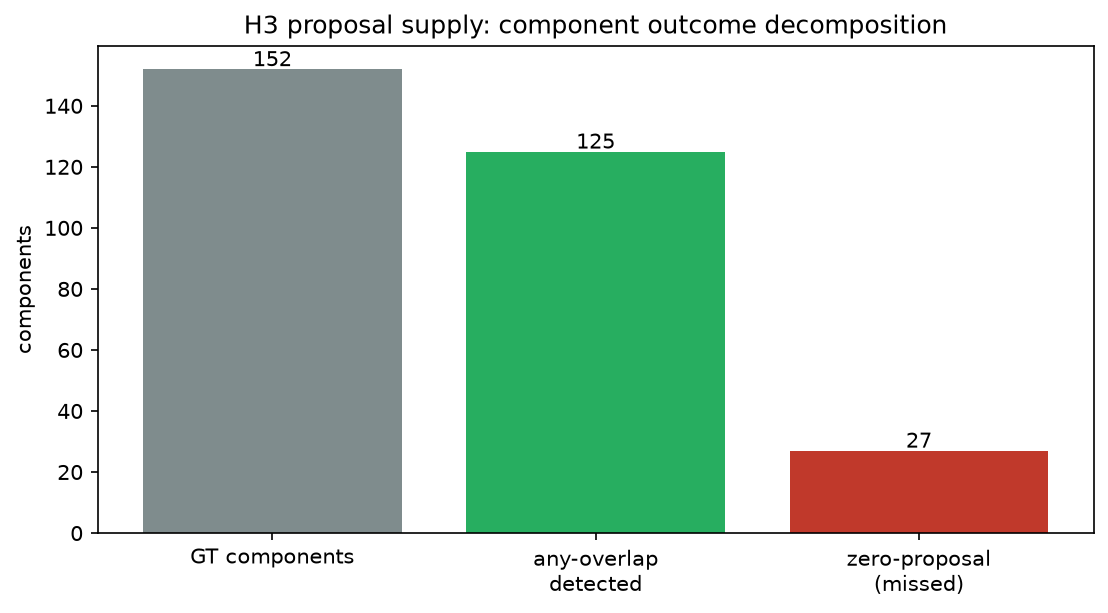

All values above are DESCRIPTIVE_SUPPORTING_METRIC__NOT_H3_GATE


In [7]:
# ── Phasewise evaluation / visualization synchronization (post-audit) ─────────
import json as _json, hashlib as _hashlib
from pathlib import Path as _Path
import numpy as _np
import pandas as _pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as _plt
try:
    from IPython.display import display as _disp, Image as _Img
except Exception:
    _disp = print; _Img = None
_ROOT = _Path('D:/Softfors/jup')
_AUD = _ROOT / 'reports' / 'audits'
_TAB = _ROOT / 'reports' / 'tables'
_FIG = _ROOT / 'reports' / 'figures' / 'phasewise_sync'
_FIG.mkdir(parents=True, exist_ok=True)
def _sha(p): return _hashlib.sha256(_Path(p).read_bytes()).hexdigest()
def _load(p): return _json.loads(_Path(p).read_text(encoding='utf-8'))
def _show(p, w=840):
    if _Img is not None and _Path(p).exists():
        _disp(_Img(filename=str(p), width=w))
LBL      = 'DESCRIPTIVE_SUPPORTING_METRIC__NOT_PROSPECTIVE_GATE'
LBL_H3   = 'DESCRIPTIVE_SUPPORTING_METRIC__NOT_H3_GATE'
LBL_STAT = 'DESCRIPTIVE_POST_HOC_STATISTICAL_SUPPORT'

psum = _pd.read_csv(_TAB / 'project_evaluation_proposal_metrics_summary.csv')
h3 = psum[psum['arm'].str.contains('H3')]
_disp(h3)

h3c = _pd.read_csv(_TAB / 'h3_supply_eval_per_component.csv')
tot = int(len(h3c)); det = int(h3c['any_overlap'].sum())
zero = tot - det
tiny = h3c[h3c['size_stratum'] == 'TINY']
_disp(_pd.DataFrame([{
    'gt_components': tot, 'any_overlap_detected': det, 'zero_proposal_components': zero,
    'zero_proposal_rate': zero / tot,
    'tiny_gt': int(len(tiny)), 'tiny_zero_proposal': int((~tiny['any_overlap']).sum()),
    'metric_domain': 'CAUSAL_COUNTERFACTUAL_DIAGNOSTIC', 'label': LBL_H3,
}]).round(6))

fig, ax = _plt.subplots(figsize=(7.5, 4.2))
ax.bar(['GT components', 'any-overlap\ndetected', 'zero-proposal\n(missed)'], [tot, det, zero],
       color=['#7f8c8d', '#27ae60', '#c0392b'])
for i, v in enumerate([tot, det, zero]):
    ax.text(i, v + 1, str(v), ha='center', fontsize=10)
ax.set_ylabel('components'); ax.set_title('H3 proposal supply: component outcome decomposition')
_plt.tight_layout(); _p = _FIG / 'h3_02_component_outcomes.png'
_plt.savefig(str(_p), dpi=150, bbox_inches='tight'); _plt.show(); _show(_p)

print('All values above are', LBL_H3)